# Netflix Content Rating & Genre Analysis

---

## Project Overview

This notebook analyzes Netflix content ratings and genres to examine content classification, identify the most common genres, and compare rating distributions between Movies and TV Shows.

The analysis also explores how rating categories and genre classifications can provide insights into potential audience segmentation based on content characteristics.

---

### Objectives

1. Analyze the distribution of Netflix content rating categories.
2. Identify the most common genres in the dataset.
3. Compare rating distributions between Movies and TV Shows.
4. Create interactive visualizations to present analytical findings.
5. Generate business insights related to content characteristics and potential audience targeting.

### Dataset

The analysis uses the cleaned Netflix dataset generated in Notebook 01.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly

### Expected Deliverables

- Content rating distribution summary.
- Most common genre rankings.
- Rating comparison between Movies and TV Shows.
- Interactive data visualizations.
- Key findings and business insights.

---

## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid')

## Data Loading

In [3]:
# Load cleaned Netflix dataset
file_path = Path("../Dataset/Cleaned_Netflix_Data.csv")
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

Dataset loaded successfully!
Total Records: 8,786
Total Columns: 10


### Preview Dataset

In [4]:
# Display dataset information
print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (8786, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


### Inspect dataset structure

In [5]:
# Inspect dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8786 non-null   object
 1   type          8786 non-null   object
 2   title         8785 non-null   object
 3   director      6199 non-null   object
 4   country       8499 non-null   object
 5   date_added    8786 non-null   object
 6   release_year  8786 non-null   int64 
 7   rating        8786 non-null   object
 8   duration      8786 non-null   object
 9   listed_in     8786 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.5+ KB


## Initial Rating and Genre Data Exploration

This section explores the rating and genre columns to understand their data structure, category distribution, and data quality. The initial inspection provides a foundation for preparing the data for further categorical analysis.## Initial Rating and Genre Data Exploration

This section explores the rating and genre columns to understand their data structure, category distribution, and data quality. The initial inspection provides a foundation for preparing the data for further categorical analysis.

## Rating and Genre Data Overview

This section provides an overview of the rating and genre attributes, including their data types, missing values, and number of unique entries. Understanding these characteristics helps determine how the data should be processed for subsequent analysis.

In [6]:
# Inspect rating and genre columns
rating_genre_overview = pd.DataFrame({
    'Column': ['rating', 'listed_in'],
    'Data Type': [
        df['rating'].dtype,
        df['listed_in'].dtype
    ],
    'Missing Values': [
        df['rating'].isna().sum(),
        df['listed_in'].isna().sum()
    ],
    'Unique Values': [
        df['rating'].nunique(),
        df['listed_in'].nunique()
    ]
})

display(rating_genre_overview)

,Column,Data Type,Missing Values,Unique Values
0,rating,object,0,14
1,listed_in,object,0,513


### Inspect Rating Categories

This subsection examines the available content rating categories and their frequency across the dataset. The analysis helps identify the most common rating classifications and understand how Netflix content is distributed across different rating categories.

In [7]:
# Display unique rating categories
print("Unique Rating Categories:")
display(sorted(df['rating'].dropna().unique()))

# Count titles by rating category
rating_counts = (
    df['rating']
    .value_counts(dropna=False)
    .rename_axis('rating')
    .reset_index(name='total_titles')
)

display(rating_counts)

Unique Rating Categories:


['G',
 'NC-17',
 'NR',
 'PG',
 'PG-13',
 'R',
 'TV-14',
 'TV-G',
 'TV-MA',
 'TV-PG',
 'TV-Y',
 'TV-Y7',
 'TV-Y7-FV',
 'UR']

,rating,total_titles
0,TV-MA,3204
1,TV-14,2155
2,TV-PG,861
3,R,798
4,PG-13,490
5,TV-Y7,333
6,TV-Y,306
7,PG,287
8,TV-G,220
9,NR,79


### Inspect Genre Categories

This subsection examines the genre information stored in the `listed_in` column. Since each title can be associated with multiple genres, the initial inspection helps identify how genre information is represented and prepares the data for individual genre frequency analysis.

In [8]:
# Display sample genre entries
print("Sample Genre Entries:")
display(df['listed_in'].head(10))

# Count unique genre entries
print("Total Unique Genre Entries:", df['listed_in'].nunique())

Sample Genre Entries:


0                                        Documentaries
1    Crime TV Shows, International TV Shows, TV Act...
2                   TV Dramas, TV Horror, TV Mysteries
3                   Children & Family Movies, Comedies
4     Dramas, Independent Movies, International Movies
5                         British TV Shows, Reality TV
6                                     Comedies, Dramas
7    Children & Family Movies, Comedies, Music & Mu...
8                         Dramas, International Movies
9           Children & Family Movies, Music & Musicals
Name: listed_in, dtype: object

Total Unique Genre Entries: 513


### Rating and Genre Data Consistency

This subsection checks the consistency of rating and genre entries, particularly for leading or trailing whitespace and empty values. These checks help ensure that category labels are represented consistently before conducting further analysis.

In [9]:
# Check whitespace inconsistencies
rating_whitespace = (
    df['rating']
    .dropna()
    .str.strip()
    .ne(df['rating'].dropna())
    .sum()
)

genre_whitespace = (
    df['listed_in']
    .dropna()
    .str.strip()
    .ne(df['listed_in'].dropna())
    .sum()
)

print("Rating entries with leading/trailing whitespace:", rating_whitespace)
print("Genre entries with leading/trailing whitespace:", genre_whitespace)

Rating entries with leading/trailing whitespace: 0
Genre entries with leading/trailing whitespace: 0


## Content Rating Analysis

This section analyzes the distribution of content ratings across the Netflix catalog. By examining the frequency and proportion of each rating category, the analysis identifies the most commonly represented classifications in the dataset.

### Rating Distribution

This subsection calculates the number and percentage of titles within each rating category. The results provide an overview of how content is distributed across different rating classifications.

In [10]:
# Calculate rating distribution
rating_distribution = (
    df['rating']
    .value_counts()
    .rename_axis('rating')
    .reset_index(name='total_titles')
)

# Calculate percentage
rating_distribution['percentage'] = (
    rating_distribution['total_titles'] / len(df) * 100
)

display(rating_distribution)

,rating,total_titles,percentage
0,TV-MA,3204,36.47
1,TV-14,2155,24.53
2,TV-PG,861,9.80
3,R,798,9.08
4,PG-13,490,5.58
5,TV-Y7,333,3.79
6,TV-Y,306,3.48
7,PG,287,3.27
8,TV-G,220,2.50
9,NR,79,0.90


### Rating Distribution Visualization

This visualization presents the number of titles in each rating category. A horizontal bar chart is used to make category labels easier to read and facilitate comparisons across rating classifications.

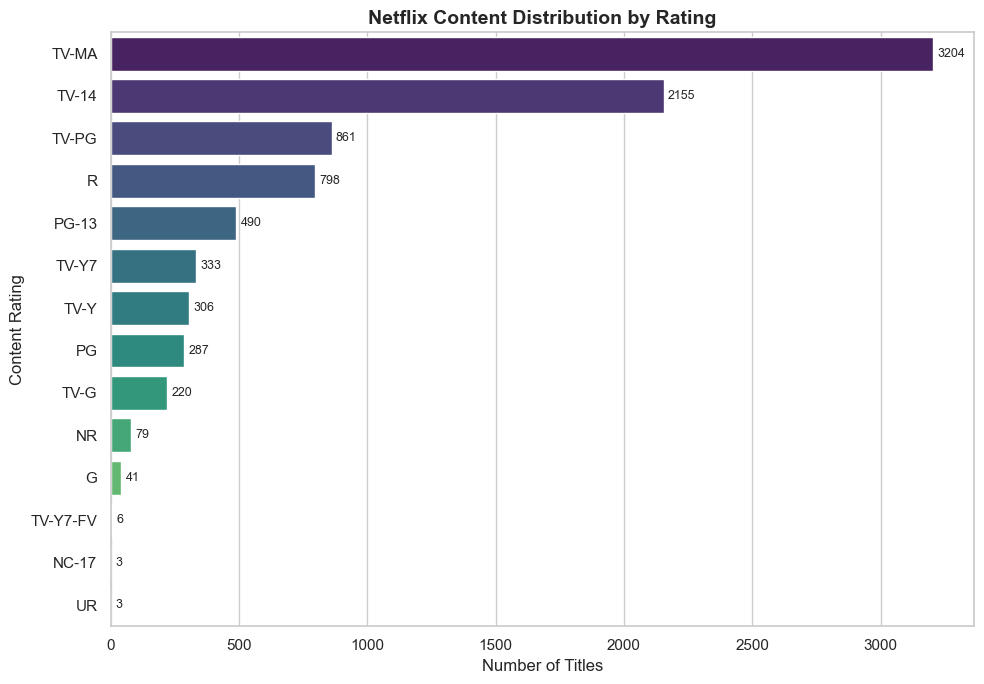

In [11]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=rating_distribution,
    x='total_titles',
    y='rating',
    hue='rating',
    palette='viridis',
    legend=False
)

plt.title('Netflix Content Distribution by Rating', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.0f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

## Genre Distribution Analysis

This section analyzes the distribution of genres across the Netflix catalog. Since each title can be associated with multiple genres, the genre data will be separated into individual categories to identify the most frequently represented genres.

### Genre Frequency

This subsection calculates the frequency of individual genres across all titles. The genre entries are separated using commas so that each genre can be counted independently, rather than treating combinations of genres as a single category.

In [12]:
# Split genre entries into individual genres
genre_data = (
    df['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
)

# Calculate genre frequency
genre_counts = (
    genre_data
    .value_counts()
    .rename_axis('genre')
    .reset_index(name='total_titles')
)

# Calculate percentage
genre_counts['percentage'] = (
    genre_counts['total_titles'] / len(df) * 100
)

display(genre_counts.head(20))

,genre,total_titles,percentage
0,International Movies,2751,31.31
1,Dramas,2423,27.58
2,Comedies,1673,19.04
3,International TV Shows,1348,15.34
4,Documentaries,869,9.89
5,Action & Adventure,859,9.78
6,TV Dramas,761,8.66
7,Independent Movies,755,8.59
8,Children & Family Movies,641,7.30
9,Romantic Movies,616,7.01


### Genre Distribution Visualization

This visualization highlights the 20 most frequently represented genres in the Netflix catalog. A horizontal bar chart is used to compare genre frequencies and make category labels easier to read.

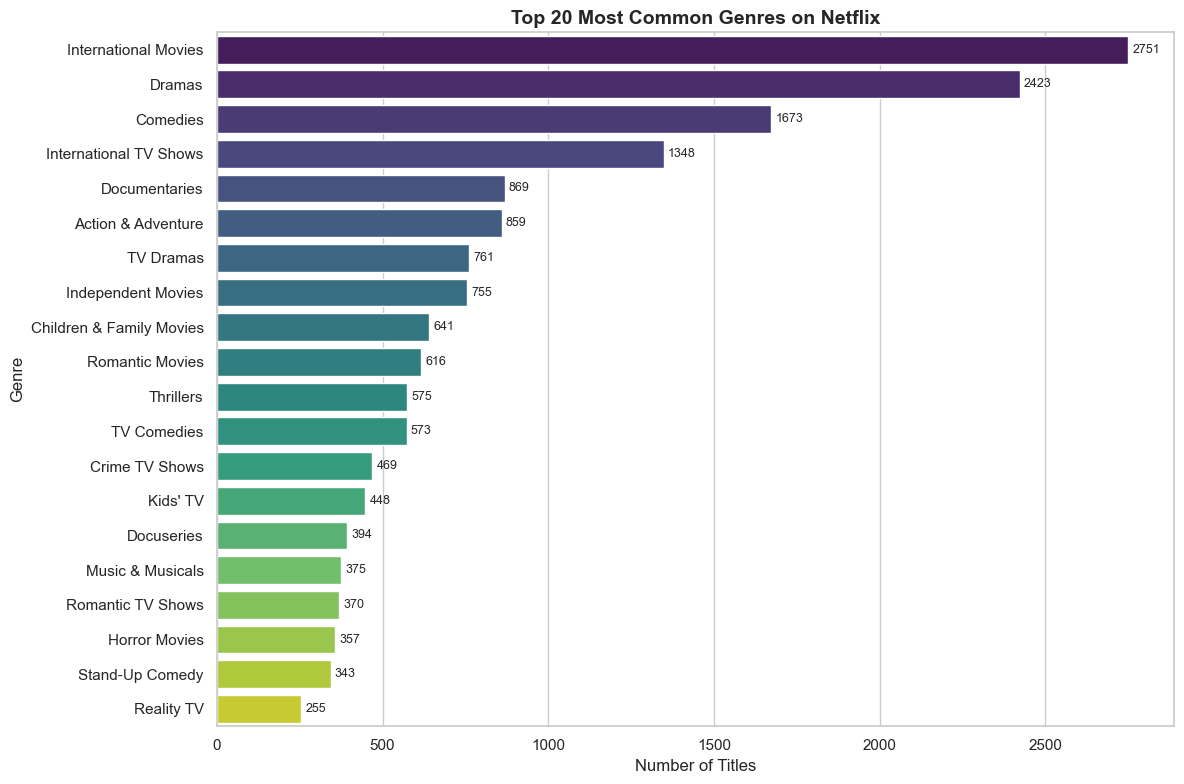

In [13]:
plt.figure(figsize=(12, 8))

top_20_genres = genre_counts.head(20)

sns.barplot(
    data=top_20_genres,
    x='total_titles',
    y='genre',
    hue='genre',
    palette='viridis',
    legend=False
)

for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.title('Top 20 Most Common Genres on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

## Rating Comparison by Content Type

This section compares the distribution of content ratings between Movies and TV Shows. The analysis aims to identify differences in rating classifications and understand how each content type is represented across the available rating categories.

### Rating Distribution by Content Type

This subsection calculates the number of titles for each rating category, grouped by content type. The results provide a direct comparison of rating classifications between Movies and TV Shows.

In [14]:
# Calculate rating distribution by content type
rating_by_type = (
    df.groupby(['rating', 'type'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(rating_by_type)

type,rating,Movie,TV Show
0,G,41,0
1,NC-17,3,0
2,NR,75,4
3,PG,287,0
4,PG-13,490,0
5,R,796,2
6,TV-14,1426,729
7,TV-G,126,94
8,TV-MA,2061,1143
9,TV-PG,540,321


### Rating Percentage by Content Type

This subsection calculates the percentage of each rating category within Movies and TV Shows separately. Using percentages allows a fairer comparison between the two content types despite differences in their total number of titles.

In [15]:
# Calculate rating distribution by content type
rating_percentage = (
    df.groupby(['type', 'rating'])
    .size()
    .reset_index(name='total_titles')
)

# Calculate percentage within each content type
rating_percentage['percentage'] = (
    rating_percentage['total_titles'] /
    rating_percentage.groupby('type')['total_titles'].transform('sum') * 100
)

# Reshape the table for comparison
rating_percentage = rating_percentage.pivot(
    index='rating',
    columns='type',
    values='percentage'
).fillna(0).reset_index()

display(rating_percentage.round(2))

type,rating,Movie,TV Show
0,G,0.67,0.00
1,NC-17,0.05,0.00
2,NR,1.22,0.15
3,PG,4.69,0.00
4,PG-13,8.00,0.00
5,R,13.00,0.08
6,TV-14,23.29,27.38
7,TV-G,2.06,3.53
8,TV-MA,33.66,42.92
9,TV-PG,8.82,12.05


### Rating Comparison Visualization

This visualization compares the percentage distribution of each rating category between Movies and TV Shows. A grouped horizontal bar chart is used to highlight differences in rating composition across the two content types.

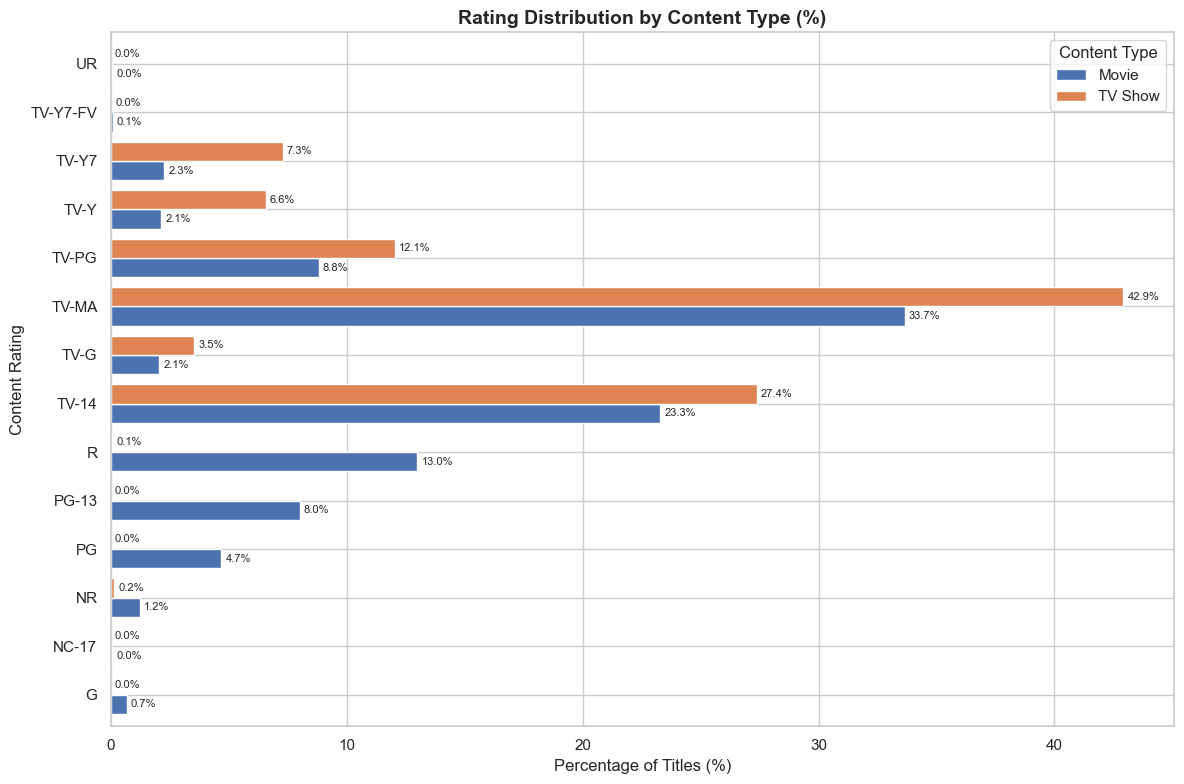

In [16]:
rating_percentage_plot = rating_percentage.set_index('rating')

ax = rating_percentage_plot.plot(
    kind='barh',
    figsize=(12, 8),
    width=0.8
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=8
    )

plt.title('Rating Distribution by Content Type (%)', fontsize=14, fontweight='bold')
plt.xlabel('Percentage of Titles (%)')
plt.ylabel('Content Rating')
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

## Interactive Visualizations

This section presents interactive visualizations to explore rating and genre distributions. Plotly is used to provide interactive features, allowing users to examine category frequencies and percentages through hover information.


### Interactive Rating Distribution

This visualization displays the distribution of Netflix content ratings using an interactive bar chart. Users can hover over each bar to view the number and percentage of titles within each rating category.

In [17]:
fig = px.bar(
    rating_distribution,
    x='rating',
    y='total_titles',
    hover_data={
        'rating': True,
        'total_titles': True,
        'percentage': ':.2f'
    },
    title='Interactive Netflix Content Rating Distribution',
    labels={
        'rating': 'Content Rating',
        'total_titles': 'Number of Titles',
        'percentage': 'Percentage (%)'
    },
    color='total_titles',
    color_continuous_scale='Viridis'
)

fig.update_layout(
    xaxis_title='Content Rating',
    yaxis_title='Number of Titles',
    xaxis={'categoryorder': 'total descending'}
)

fig.show()

### Interactive Genre Distribution

This visualization presents the 20 most frequently represented genres using an interactive bar chart. Users can hover over each bar to explore the number and percentage of titles associated with each genre.

In [18]:
# Create interactive top 20 genre visualization
fig = px.bar(
    top_20_genres,
    x='total_titles',
    y='genre',
    orientation='h',
    title='Interactive Top 20 Netflix Genres',
    color='total_titles',
    color_continuous_scale='Viridis',
    text='total_titles',
    labels={
        'total_titles': 'Number of Titles',
        'genre': 'Genre'
    }
)

fig.update_traces(
    texttemplate='%{text:.0f}',
    textposition='outside'
)

# Match the exact order of the Seaborn chart
fig.update_yaxes(
    categoryorder='array',
    categoryarray=top_20_genres['genre'].tolist(),
    autorange='reversed'
)

fig.update_layout(
    height=900,
    width=1200,
    title_x=0.5,
    margin=dict(l=220, r=100, t=100, b=80),
    xaxis_title='Number of Titles',
    yaxis_title='Genre'
)

fig.show()

## Genre Distribution by Content Type

This section compares genre distributions between Movies and TV Shows to identify differences in genre representation across content types.

In [19]:
# Split genre entries and expand them into individual rows
genre_by_type = df[['type', 'listed_in']].copy()

genre_by_type['genre'] = genre_by_type['listed_in'].str.split(', ')

genre_by_type = genre_by_type.explode('genre')

# Remove unnecessary columns
genre_by_type = genre_by_type[['type', 'genre']]

# Calculate genre frequency by content type
genre_type_counts = (
    genre_by_type
    .groupby(['type', 'genre'])
    .size()
    .reset_index(name='total_titles')
)

# Display the 10 most common genres for each content type
top_10_genres_by_type = (
    genre_type_counts
    .sort_values(['type', 'total_titles'], ascending=[True, False])
    .groupby('type')
    .head(10)
    .reset_index(drop=True)
)

display(top_10_genres_by_type)

,type,genre,total_titles
0,Movie,International Movies,2751
1,Movie,Dramas,2423
2,Movie,Comedies,1673
3,Movie,Documentaries,869
4,Movie,Action & Adventure,859
5,Movie,Independent Movies,755
6,Movie,Children & Family Movies,641
7,Movie,Romantic Movies,616
8,Movie,Thrillers,575
9,Movie,Music & Musicals,375


### Top 10 Genres by Content Type

This subsection identifies the ten most frequently represented genres for Movies and TV Shows. The results provide a comparison of genre composition across both content types.

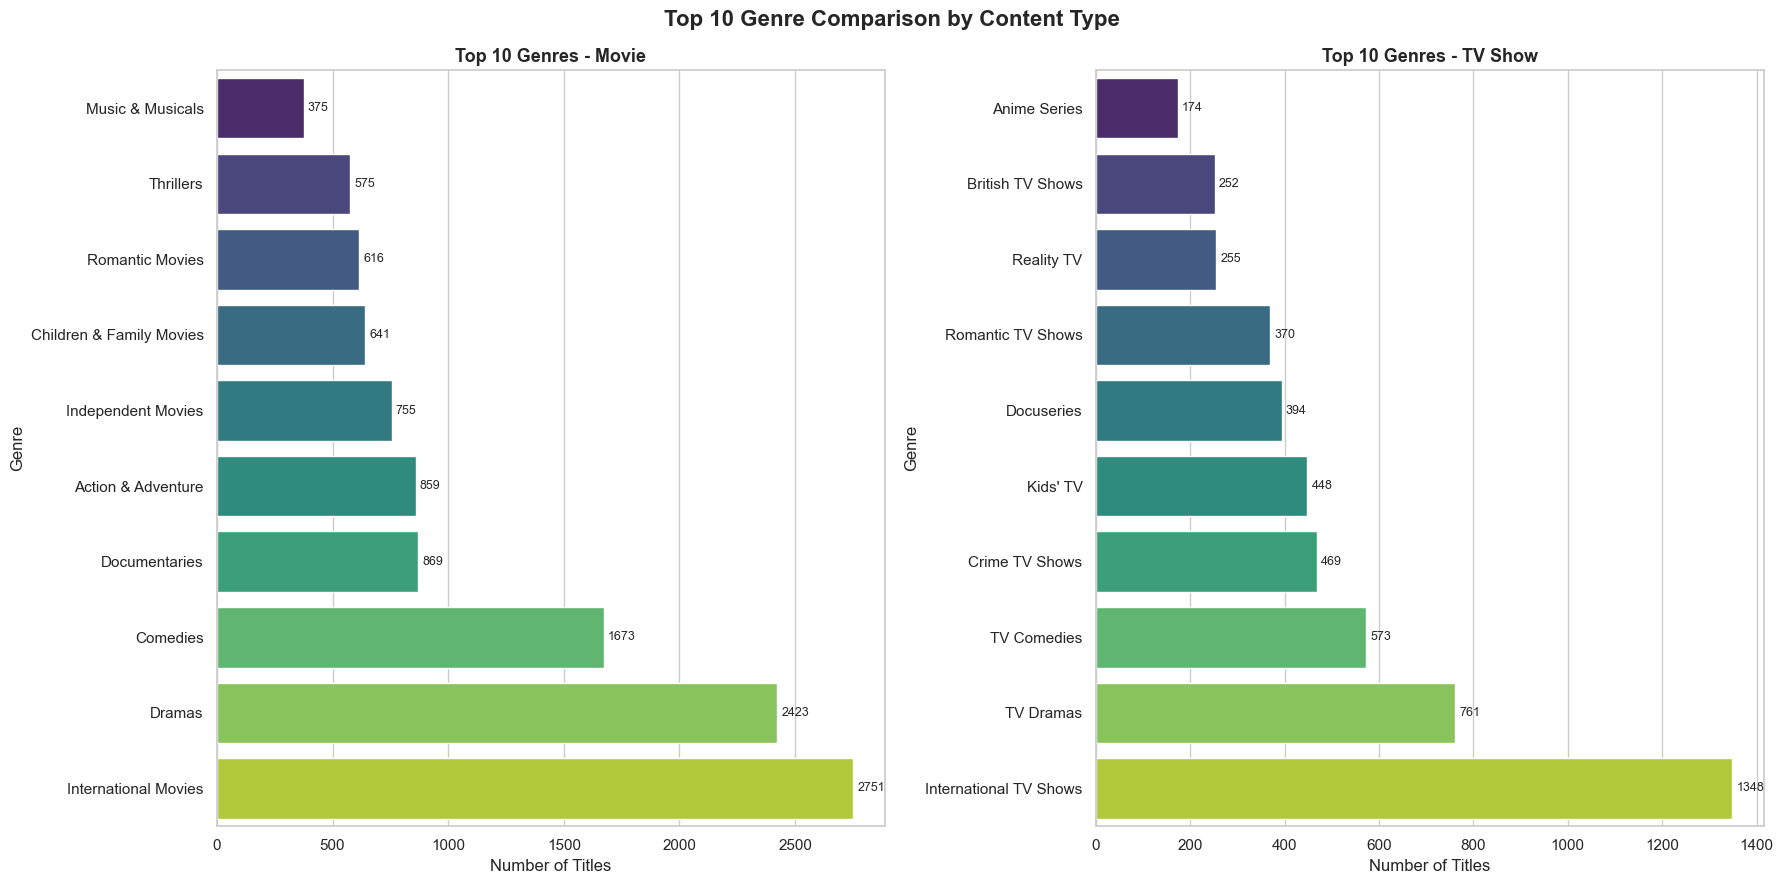

In [20]:
# Create separate plots for Movies and TV Shows
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

content_types = ['Movie', 'TV Show']

for ax, content_type in zip(axes, content_types):
    plot_data = (
        top_10_genres_by_type[
            top_10_genres_by_type['type'] == content_type
        ]
        .sort_values('total_titles', ascending=True)
    )

    sns.barplot(
        data=plot_data,
        x='total_titles',
        y='genre',
        hue='genre',
        palette='viridis',
        legend=False,
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

    ax.set_title(f'Top 10 Genres - {content_type}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Number of Titles')
    ax.set_ylabel('Genre')

plt.suptitle(
    'Top 10 Genre Comparison by Content Type',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


## Key Findings and Business Insights

The analysis of Netflix content ratings and genres reveals several patterns in content classification and catalog composition. The following findings summarize the main results from the rating distribution, genre frequency, and comparisons across content types.



### Key Findings

1. **TV-MA Is the Most Common Content Rating**  
   TV-MA represents 3,204 titles (36.47%) of the dataset, followed by TV-14 with 2,155 titles (24.53%). Together, these two categories account for approximately 61% of all titles, indicating a strong representation of mature and teen-oriented content classifications.

2. **International Movies and Dramas Are the Most Frequent Genres**  
   International Movies is the most frequently represented genre, with 2,751 titles (31.31%), followed by Dramas with 2,423 titles (27.58%) and Comedies with 1,673 titles (19.04%). These results indicate that international content, drama, and comedy have substantial representation in the catalog.

3. **TV-MA Dominates Both Movies and TV Shows**  
   TV-MA accounts for 33.66% of Movies and 42.92% of TV Shows. TV-14 is the second most common rating for both content types, representing 23.29% of Movies and 27.38% of TV Shows.

4. **Rating Composition Differs Between Movies and TV Shows**  
   Movie titles have higher proportions of film-oriented classifications such as R (13.00%), PG-13 (8.00%), and PG (4.69%). Meanwhile, TV Shows have higher proportions of TV-Y (6.57%), TV-Y7 (7.29%), and TV-PG (12.05%). This demonstrates differences in rating composition between the two content types.

5. **Genre Representation Reflects Different Content-Type Characteristics**  
   International Movies (2,751 titles) and Dramas (2,423 titles) lead the Movie genre distribution. For TV Shows, International TV Shows (1,348 titles) and TV Dramas (761 titles) are the most frequently represented genres.

### Business Insights

The rating distribution suggests that mature and teen-oriented classifications represent a substantial portion of the Netflix catalog. This information can help describe the catalog's content classification profile and support content categorization or metadata-based content planning.

The differences in rating composition between Movies and TV Shows also highlight the importance of analyzing each content type separately. For example, TV Shows have relatively higher proportions of TV-Y and TV-Y7 classifications, while Movies have higher proportions of R and PG-13 classifications. These patterns can support more detailed content segmentation and catalog organization.

Genre analysis further indicates that international content and drama-related categories have strong representation across both content types. These findings can help identify prominent catalog categories and provide a basis for further analysis of content diversity and classification.

### Analysis Limitations

This analysis is based on Netflix catalog metadata and does not include actual viewer demographics, viewing behavior, audience preferences, or engagement metrics. Therefore, rating categories should be interpreted as content classifications rather than direct evidence of audience demographics. Additionally, titles can belong to multiple genres, so genre percentages are not mutually exclusive and may exceed 100% when combined.
